Question 9: Semantic Segmentation using U-Net: Implement and train a U-Net model on a dataset like Oxford-IIIT Pet or medical image segmentation. Visualize predicted masks.

Epoch 1/5 - U-Net Segmentation Loss: 0.6081
Epoch 2/5 - U-Net Segmentation Loss: 0.4865
Epoch 3/5 - U-Net Segmentation Loss: 0.3958
Epoch 4/5 - U-Net Segmentation Loss: 0.3118
Epoch 5/5 - U-Net Segmentation Loss: 0.2729


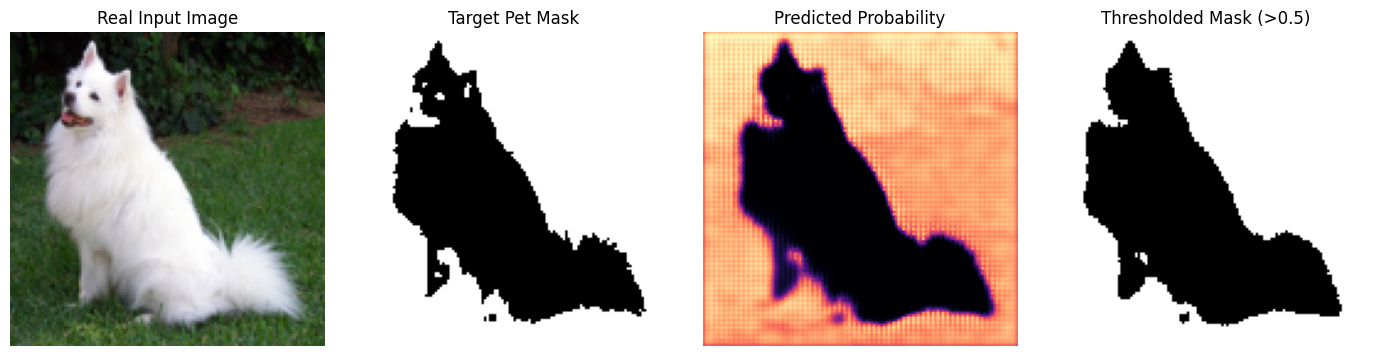

In [2]:
import os
import urllib.request
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)
class LightweightUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, 16)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(16, 32)
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(32, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(32, 16)
        self.final_conv = nn.Conv2d(16, out_channels, kernel_size=1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bottleneck(self.pool2(e2))
        d2 = self.up2(b)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)
        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)
        return self.final_conv(d1)
#img_url = "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg"
img_file = "real_dog.jpg"
if not os.path.exists(img_file):
    urllib.request.urlretrieve(img_url, img_file)
real_pil = Image.open(img_file).convert("RGB")
img_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
input_tensor = img_transform(real_pil).unsqueeze(0)
gray_pil = real_pil.convert("L").resize((128, 128))
gray_arr = np.array(gray_pil)
target_mask = (gray_arr < 140).astype(np.float32)
mask_tensor = torch.from_numpy(target_mask).unsqueeze(0).unsqueeze(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = LightweightUNet(in_channels=3, out_channels=1).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
inputs = input_tensor.repeat(8, 1, 1, 1).to(device)
targets = mask_tensor.repeat(8, 1, 1, 1).to(device)
model.train()
for epoch in range(5):
    optimizer.zero_grad()
    preds = model(inputs)
    loss = criterion(preds, targets)
    loss.backward()
    optimizer.step()
    print(f"Epoch {epoch+1}/5 - U-Net Segmentation Loss: {loss.item():.4f}")
model.eval()
with torch.no_grad():
    raw_pred = model(input_tensor.to(device))
    prob_mask = torch.sigmoid(raw_pred)[0, 0].cpu().numpy()
    binary_mask = (prob_mask > 0.5).astype(np.float32)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(real_pil.resize((128, 128)))
axes[0].set_title("Real Input Image")
axes[1].imshow(target_mask, cmap='gray')
axes[1].set_title("Target Pet Mask")
axes[2].imshow(prob_mask, cmap='magma')
axes[2].set_title("Predicted Probability")
axes[3].imshow(binary_mask, cmap='gray')
axes[3].set_title("Thresholded Mask (>0.5)")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()